# Radar de Licitaciones — Exploración y preparación de los datos

**Milton Beltrán** · Natural Language Processing · Proyecto final

**Fuente:** API OCDS de Guatecompras ([`ocds.guatecompras.gt/files`](https://ocds.guatecompras.gt/files)), Ministerio de Finanzas Públicas, licencia CC BY 4.0.

> ✍️ **[Milton: escribir]** Párrafo de introducción: qué es el radar y qué cubre este notebook (extracción, EDA, transformación).

## 0. Preparación del entorno

In [1]:
# --- 0.1 Librerías y conexión ---
# El notebook importa la lógica de src/; aquí solo se explora y se documenta.
import json
import re
import sys
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.captura import ocds_client
from src.captura.extraer import leer_mes
from src.db import RUTA_DB
from src.limpieza.normalizar import RUIDO, para_embedding, para_tfidf, quitar_tildes, texto_entrada
import duckdb

con = duckdb.connect(str(RUTA_DB), read_only=True)
IMG = RAIZ / "img"
IMG.mkdir(exist_ok=True)
RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 120)

In [2]:
# --- 0.2 Estilo de las gráficas ---
# Una sola serie por gráfica: acento del deck; lo que no se resalta va en gris.
ACENTO, GRIS, TINTA, TINTA_2 = "#5543D1", "#B9B6AE", "#1E2329", "#5C636B"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.size": 10,
    "axes.edgecolor": "#D5D3CC", "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ECEAE4", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
})
miles = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")

## 1. Definición del problema

> ✍️ **[Milton: escribir]** Definición final del problema en 1–2 frases (usuario, qué recibe, qué decide). Después: por qué un filtro por categoría o palabra clave no basta (los tres casos), y el criterio de relevancia que vamos a usar para etiquetar. Apoyarse en los números de las secciones 2 y 3: volumen diario real, % de compra directa, % de títulos con "software" que no son software.

## 2. Extracción de datos

In [3]:
# --- 2.1 Índice de la API ---
indice = pd.DataFrame(ocds_client.indice())
indice["timestamp"] = pd.to_datetime(indice["timestamp"], utc=True).dt.tz_convert("America/Guatemala")
print(f"Meses publicados: {len(indice)} ({indice['id'].iloc[-1]} … {indice['id'].iloc[0]})")
print(f"Última regeneración: {indice['timestamp'].max():%Y-%m-%d %H:%M} (hora de Guatemala)")
indice[["id", "year", "month", "timestamp"]].head(3)

Meses publicados: 82 (gc-2020-1 … gc-2026-10)
Última regeneración: 2026-10-27 04:16 (hora de Guatemala)


,id,year,month,timestamp
0,gc-2026-10,2026,10,2026-10-27 03:19:47.661137-06:00
1,gc-2026-9,2026,9,2026-10-27 03:50:24.568156-06:00
2,gc-2026-8,2026,8,2026-10-27 03:53:34.699456-06:00


In [4]:
# --- 2.2 Un registro tal como lo entrega la API ---
# El JSON del mes llega dentro de un ZIP. Se muestra solo la parte de tender que usamos.
ruta = ocds_client.ruta_mes(2026, 9)
with zipfile.ZipFile(ruta) as z:
    print(f"{ruta.name}: {ruta.stat().st_size / 1e6:.0f} MB comprimido → "
          f"{z.infolist()[0].file_size / 1e6:.0f} MB de JSON ({z.infolist()[0].filename})")
    paquete = json.loads(z.read(z.infolist()[0]))

registros = paquete["records"]
r = registros[2]
t = r["compiledRelease"]["tender"]
print(f"Records en el mes: {len(registros):,}\n")
print(json.dumps({
    "ocid": r["ocid"],
    "tender": {k: t.get(k) for k in ["id", "title", "description", "status", "procurementMethod",
                                     "procurementMethodDetails", "mainProcurementCategory", "tenderPeriod", "value"]}
    | {"items[0]": {k: t["items"][0].get(k) for k in ["description", "classification", "attributes"]}},
    "buyer": r["compiledRelease"]["buyer"],
}, ensure_ascii=False, indent=1))

2026-09.zip: 37 MB comprimido → 267 MB de JSON (2026-09_Guatecompras.json)


Records en el mes: 35,401

{
 "ocid": "ocds-xqjsxa-31800912",
 "tender": {
  "id": "GT-NOG-31800912",
  "title": "COMPRA DIRECTA, COMPRA POR FONDO ROTATIVO, SERVICIO DE ATENCION PARA AUTORIDADES SUPERIORES Y LOCALES (ALIMENTOS), COMPRA DE AGUA PURA.",
  "description": null,
  "status": "complete",
  "procurementMethod": "open",
  "procurementMethodDetails": "Procedimientos regulados por el artículo 54 LCE",
  "mainProcurementCategory": "services",
  "tenderPeriod": {
   "startDate": "2026-09-01T14:29:20-06:00",
   "endDate": "2026-09-01T14:44:41-06:00"
  },
  "value": null,
  "items[0]": {
   "description": "SERVICIO DE ATENCION PARA AUTORIDADES SUPERIORES Y LOCALES (ALIMENTOS), COMPRA DE AGUA PURA.",
   "classification": {
    "scheme": "UNSPSC",
    "id": "93131608"
   },
   "attributes": [
    {
     "value": "Obligatorio salvo excepciones",
     "id": "9FA4F6EECD4067ABE3C575296B64DEB9",
     "name": "Tipo de obligatoriedad"
    },
    {
     "value": "SERVICIO DE ATENCION PARA AUTO

In [5]:
# --- 2.3 Campos del estándar OCDS que Guatecompras sí llena ---
def presente(tender, campo):
    v = tender.get(campo)
    return v not in (None, "", [], {})

campos = ["title", "description", "items", "value", "tenderPeriod", "procurementMethod",
          "procurementMethodDetails", "mainProcurementCategory", "documents"]
tenders = [rec["compiledRelease"].get("tender") or {} for rec in registros]
presencia = pd.Series({c: np.mean([presente(td, c) for td in tenders]) for c in campos}, name="% con dato")
print("procurementMethod distintos:", {td.get("procurementMethod") for td in tenders})
(presencia * 100).round(1).to_frame()

procurementMethod distintos: {'open'}


,% con dato
title,100.0
description,0.0
items,100.0
value,0.0
tenderPeriod,100.0
procurementMethod,100.0
procurementMethodDetails,100.0
mainProcurementCategory,99.6
documents,100.0


In [6]:
# --- 2.4 Carga histórica ---
# python -m src.captura.actualizar --desde 2024-01  (idempotente: el SHA evita reprocesar)
corridas = con.sql("""
    SELECT mes_archivo, estado, nuevos, actualizados, fecha
    FROM corridas QUALIFY row_number() OVER (PARTITION BY mes_archivo ORDER BY fecha DESC) = 1
    ORDER BY fecha
""").df()
zips = sorted(ocds_client.CRUDOS.glob("*.zip"))
print(f"Meses cargados: {len(corridas)} · ZIP en disco: {sum(p.stat().st_size for p in zips) / 1e9:.2f} GB")
print(f"Errores: {(corridas['estado'] == 'error').sum()}")
con.sql("SELECT count(*) AS procesos, count(DISTINCT ocid) AS ocid_unicos, min(fecha_publicacion) AS desde, max(fecha_publicacion) AS hasta FROM procesos").df()

Meses cargados: 34 · ZIP en disco: 1.01 GB
Errores: 0


,procesos,ocid_unicos,desde,hasta
0,937949,937949,2024-01-02 10:34:22,2026-10-26 23:55:52


## 3. Análisis exploratorio

In [7]:
# --- 3.1 Datos a pandas ---
df = con.sql("""
    SELECT ocid, nog, titulo, items_texto, caracteristicas, n_items, unspsc, entidad,
           modalidad, categoria, estado, fecha_publicacion, fecha_inicio, fecha_cierre, mes_archivo
    FROM procesos
""").df()
df["dias_oferta"] = (df["fecha_cierre"] - df["fecha_inicio"]).dt.total_seconds() / 86400
print(f"{len(df):,} procesos · {df['entidad'].nunique():,} entidades compradoras")

937,949 procesos · 638 entidades compradoras


Promedio mensual: 27,587 · por día hábil: 1,258
Procesos por año: {2024: 285594, 2025: 336529, 2026: 315826}


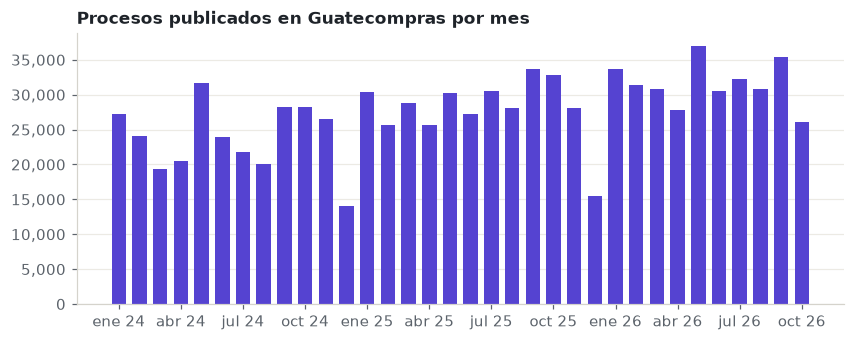

In [8]:
# --- 3.2 Volumen por mes ---
por_mes = df.groupby(df["fecha_publicacion"].dt.to_period("M")).size()
por_mes = por_mes[por_mes.index >= "2024-01"]
dias_habiles = df.loc[df["fecha_publicacion"].dt.dayofweek < 5, "fecha_publicacion"].dt.date.nunique()
habil = df["fecha_publicacion"].dt.dayofweek < 5
print(f"Promedio mensual: {por_mes.mean():,.0f} · por día hábil: {habil.sum() / dias_habiles:,.0f}")
print(f"Procesos por año: {df.groupby(df['fecha_publicacion'].dt.year).size().to_dict()}")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(por_mes.index.astype(str), por_mes.values, color=ACENTO, width=0.7)
ax.set_title("Procesos publicados en Guatecompras por mes")
ax.yaxis.set_major_formatter(miles)
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
ax.set_xticks(range(0, len(por_mes), 3), [f"{MESES[p.month - 1]} {p.year % 100}" for p in por_mes.index[::3]])
ax.grid(axis="x", visible=False)
fig.savefig(IMG / "procesos_por_mes.png")
plt.show()

In [9]:
# --- 3.3 Modalidad, categoría y estado ---
modalidad = df["modalidad"].value_counts()
tabla_mod = pd.DataFrame({"procesos": modalidad, "%": (100 * modalidad / len(df)).round(1),
                          "días de oferta (mediana)": df.groupby("modalidad")["dias_oferta"].median().round(1)})
display(tabla_mod.sort_values("procesos", ascending=False).head(8))
display(pd.concat({"categoría": df["categoria"].value_counts(normalize=True),
                   "estado": df["estado"].value_counts(normalize=True)}).mul(100).round(1).to_frame("%"))

,procesos,%,días de oferta (mediana)
modalidad,,,
Compra Directa con Oferta Electrónica (Art. 43 LCE Inciso b),854897,91.1,10.8
Cotización (Art. 38 LCE),26379,2.8,25.0
Procedimientos regulados por el artículo 54 LCE,25372,2.7,0.0
Licitación Pública (Art. 17 LCE),13867,1.5,51.9
Arrendamiento o Adquisición de Bienes Inmuebles (Art.43 inciso e),6029,0.6,0.0
Procedimientos Regulados por el artículo 44 LCE (Casos de Excepción),4092,0.4,0.1
Adquisición Directa por Ausencia de Oferta,3076,0.3,1.7
Negociaciones entre Entidades Públicas (Art. 2 LCE),2014,0.2,0.0


%
categoría goods         76.0
          services      21.7
          works          2.3
estado    complete      73.1
          withdrawn     11.9
          unsuccessful  10.0
          active         5.0

Sin periodo de ofertas: 22,138
Menos de 1 día para ofertar: 4.3%


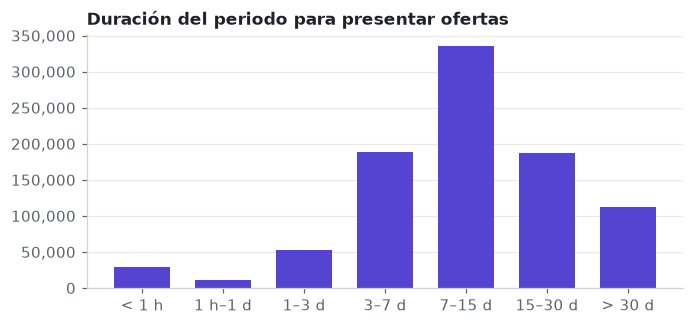

In [10]:
# --- 3.4 Periodo para ofertar ---
# Un concurso solo es accionable si queda tiempo para preparar la oferta.
cortes = [0, 1 / 24, 1, 3, 7, 15, 30, np.inf]
etiquetas = ["< 1 h", "1 h–1 d", "1–3 d", "3–7 d", "7–15 d", "15–30 d", "> 30 d"]
tramos = pd.cut(df["dias_oferta"], cortes, labels=etiquetas, right=False).value_counts(sort=False)
print(f"Sin periodo de ofertas: {df['dias_oferta'].isna().sum():,}")
print(f"Menos de 1 día para ofertar: {(df['dias_oferta'] < 1).mean():.1%}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(tramos.index.astype(str), tramos.values, color=ACENTO, width=0.7)
ax.set_title("Duración del periodo para presentar ofertas")
ax.yaxis.set_major_formatter(miles)
ax.grid(axis="x", visible=False)
fig.savefig(IMG / "duracion_ofertas.png")
plt.show()

,% vacío,mediana palabras,p90 palabras
titulo,0.0,17.0,31.0
items_texto,8.2,3.0,16.0
caracteristicas,3.6,12.0,49.0


Ítems por proceso: mediana 1, máximo 1,065


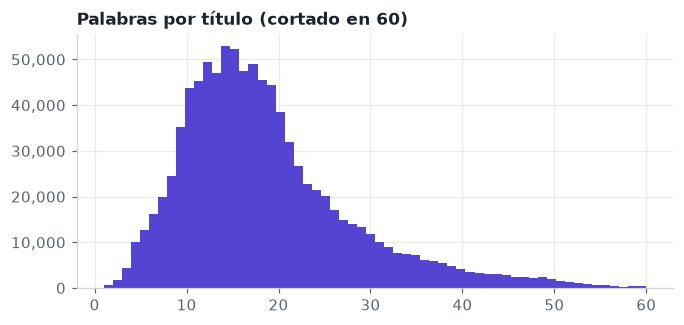

In [11]:
# --- 3.5 Cuánto texto hay ---
palabras = pd.DataFrame({c: df[c].fillna("").str.split().str.len() for c in ["titulo", "items_texto", "caracteristicas"]})
resumen_texto = pd.DataFrame({
    "% vacío": (palabras == 0).mean().mul(100).round(1),
    "mediana palabras": palabras.median(),
    "p90 palabras": palabras.quantile(0.9),
})
display(resumen_texto)
print(f"Ítems por proceso: mediana {df['n_items'].median():.0f}, máximo {df['n_items'].max():,}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(palabras["titulo"].clip(upper=60), bins=60, color=ACENTO)
ax.set_title("Palabras por título (cortado en 60)")
ax.yaxis.set_major_formatter(miles)
fig.savefig(IMG / "palabras_titulo.png")
plt.show()

In [12]:
# --- 3.6 Ruido en los títulos ---
ruido = pd.Series({
    "códigos internos (IGSS, pedido, amparo…)": df["titulo"].str.contains(RUIDO).mean(),
    "etiquetas HTML": df["titulo"].str.contains(r"<[^>]+>", regex=True).mean(),
    "todo en mayúsculas": (df["titulo"].str.upper() == df["titulo"]).mean(),
}).mul(100).round(1).to_frame("% de títulos")
display(ruido)
df.loc[df["titulo"].str.contains(RUIDO), "titulo"].sample(5, random_state=RANDOM_STATE).to_frame()

,% de títulos
"códigos internos (IGSS, pedido, amparo…)",54.9
etiquetas HTML,15.6
todo en mayúsculas,48.2


,titulo
657703,2064-Insulina Glargina Solución inyectable 100 U/ml vial 10 ml 191/2026
706781,417410 PPR 68799 OFTALMOLOGIA PROCEDIMIENTOS MEDICO QUIRURGICOS;SEGMENTO ANTERIOR POR OJO; Faco emulsificación ojo d...
812820,"COD IGSS 602 Digoxina Tableta 0.25 mg / P-1,509/2026"
702533,"PEDIDO No. 9303/2026; CODIGO IGSS: 1001003; POMALIDOMIDA, TABLETA O CAPSULA, 4 MG. DE MARCA COMERCIAL ""VAUXIMIDA""<br />"
42362,MSPAS No. 2024-CNA-CD-04 SERVICIO DE REHABILITACIÓN DEL POZO MECÁNICO DE AGUA POTABLE DEL CEMENTERIO GENERAL


In [13]:
# --- 3.7 N-gramas más frecuentes de los títulos ---
# Antes y después de quitar el ruido: lo que queda son candidatos a frases plantilla.
from sklearn.feature_extraction.text import CountVectorizer

def top_ngramas(textos, n=20):
    cv = CountVectorizer(ngram_range=(2, 3), token_pattern=r"(?u)\b[a-zñ]{2,}\b", min_df=50)
    X = cv.fit_transform(textos)
    docs_con = np.asarray((X > 0).sum(axis=0)).ravel()
    serie = pd.Series(docs_con, index=cv.get_feature_names_out()).nlargest(n)
    return [f"{g} ({100 * c / len(textos):.1f}%)" for g, c in serie.items()]

titulos = df["titulo"].sample(100_000, random_state=RANDOM_STATE)
pd.DataFrame({
    "títulos crudos": top_ngramas(titulos.map(lambda s: quitar_tildes(s.lower()))),
    "sin ruido": top_ngramas(titulos.map(lambda s: quitar_tildes(para_embedding(s).lower()))),
})

,títulos crudos,sin ruido
0,codigo igss (33.7%),adquisicion de (15.9%)
1,adquisicion de (15.9%),para el (9.8%)
2,para el (9.8%),de la (9.5%)
3,pedido no (9.7%),solucion inyectable (7.0%)
4,de la (9.5%),servicio de (6.3%)
5,no codigo (9.3%),para pacientes (5.4%)
6,no codigo igss (9.2%),de marca (5.2%)
7,pedido no codigo (8.3%),marca comercial (5.2%)
8,solucion inyectable (7.0%),mg ml (5.2%)
9,servicio de (6.3%),el hospital (5.1%)


In [14]:
# --- 3.8 Campos de formulario dentro de las características ---
# Fragmentos cortos que se repiten en miles de procesos: casi todos son requisitos del
# oferente (IVA, NIT, tiempo de entrega). Los "clave: valor" sí describen el producto y se quedan.
from collections import Counter
from src.limpieza.normalizar import RUTA_CAMPOS

frecuencia = Counter(
    f.strip().lower()
    for txt in df["caracteristicas"].dropna()
    for f in set(txt.split(" | "))
)
campos = sorted(
    (f for f, n in frecuencia.items() if f and n >= 1000 and len(f.split()) <= 8 and ":" not in f),
    key=lambda f: -frecuencia[f],
)
RUTA_CAMPOS.write_text("\n".join(campos), encoding="utf-8")

conjunto = set(campos)
con_campo = df["caracteristicas"].fillna("").map(lambda t: any(f.strip().lower() in conjunto for f in t.split(" | ")))
print(f"Campos de formulario detectados: {len(campos)} · procesos con al menos uno: {con_campo.mean():.1%}")
pd.Series({f: frecuencia[f] for f in campos[:15]}, name="procesos").to_frame()

Campos de formulario detectados: 134 · procesos con al menos uno: 21.7%


,procesos
tiempo de entrega,106340
iva,67010
regimen tributario,46686
presentacion,36153
presentación,25370
sostenimiento de oferta,24364
sostenimiento de la oferta,24002
vencimiento,22900
numero de cuenta bancaria (banrural),22383
rgae,19980


In [15]:
# --- 3.9 Filtro por palabra clave contra filtro por categoría ---
# Las dos líneas base del deck. Palabras: pre-filtro de docs/04. Categoría: UNSPSC 43
# (tecnologías de la información) y 8111 (servicios informáticos).
CLAVES = r"\b(?:software|sistemas?|plataformas?|aplicacion(?:es)?|desarrollo|licencias?|informatic\w*|tecnologi\w*|digital\w*|web)\b"
texto_plano = (df["titulo"] + " " + df["items_texto"].fillna("")).str.lower().map(quitar_tildes)
df["por_clave"] = texto_plano.str.contains(CLAVES, regex=True)
df["por_categoria"] = df["unspsc"].fillna("").str.contains(r"(?:^|,)(?:43|8111)", regex=True)

cruce = pd.crosstab(df["por_clave"], df["por_categoria"], margins=True)
cruce.index.name, cruce.columns.name = "palabra clave", "categoría TI"
print(f"Pasan por palabra clave: {df['por_clave'].mean():.1%} · por categoría: {df['por_categoria'].mean():.1%} · "
      f"por cualquiera: {(df['por_clave'] | df['por_categoria']).mean():.1%}")
cruce

Pasan por palabra clave: 5.3% · por categoría: 2.6% · por cualquiera: 7.0%


categoría TI,False,True,All
palabra clave,,,
False,872643,15322,887965
True,41289,8695,49984
All,913932,24017,937949


In [16]:
# --- 3.10 ¿Qué hay detrás de la palabra "software"? ---
# Caso 3 del deck: el software es un accesorio de un estudio médico.
con_software = df[texto_plano.str.contains(r"\bsoftware\b", regex=True)]
MEDICO = r"tomograf|resonancia|rayos[ -]?x|ultrasonido|mamograf|angiograf|equipo m[eé]dico"
medico = con_software["titulo"].str.contains(MEDICO, case=False, regex=True)
print(f"Procesos que mencionan 'software': {len(con_software):,}")
print(f"  de imágenes o equipo médico: {medico.sum():,} ({medico.mean():.1%})")
print(f"  con categoría TI: {con_software['por_categoria'].mean():.1%}")
con_software.loc[medico, ["titulo"]].sample(4, random_state=1)

Procesos que mencionan 'software': 2,271
  de imágenes o equipo médico: 394 (17.3%)
  con categoría TI: 69.9%


,titulo
528876,EVENTO 665/2025 TOMOGRAFIA COMPUTARIZADA HELICOIDAL CONVENCIONAL CARA CODIGO IGSS:224040 PPR:35086-38470 SE SOLICITA...
802636,RESONANCIA MAGNETICA CONVENCIONAL RODILLA IZQUIERDA. CODIGO IGSS: 233442 P-5728. SE SOLICITA QUE EL SERVICIO INCLUYA...
878042,TOMOGRAFIA COMPUTARIZADA HELICOIDAL VASCULAR EN 3D (ANGIOTOMOGRAFIA HELICOIDAL 3D) CON SSD MIP VRT EXTREMIDAD INFERI...
580692,EVENTO 741/2025 Tomografía Computarizada Helicoidal Vascular en tercera dimensión (angiotomografía helicoidal en ter...


In [17]:
# --- 3.11 Caso 1: software real sin categoría TI ---
# El filtro por categoría lo pierde. Se excluye lo médico para ver solo software.
perdidos = con_software[~con_software["por_categoria"] & ~medico]
print(f"Mencionan software, no son médicos y no tienen categoría TI: {len(perdidos):,}")
print("Segmentos UNSPSC más comunes:", perdidos["unspsc"].str[:2].value_counts().head(5).to_dict())
perdidos[["titulo", "unspsc"]].sample(6, random_state=3)

Mencionan software, no son médicos y no tienen categoría TI: 292
Segmentos UNSPSC más comunes: {'': 100, '80': 43, '46': 23, '86': 23, '81': 19}


,titulo,unspsc
277730,"S/C SENSOR PARA TOMA DE RADIOGRAFÍA DIGITAL INTRAORAL, QUE INCLUYA SOFTWARE PARA RESOLUCIÓN DE IMAGEN. CERTIFICADO P...",39121528
903551,"PEDIDO No. 3107-2026, SIN CÓDIGO IGSS, ARRENDAMIENTO DE ELECTROMIOGRAFO COMPUTARIZADO PARA EMG/NCS CON LA SIGUIENTE ...",93141808
152662,ADQUISICIÓN DE UNA LICENCIA DE SOFTWARE PARA ESCANEO DE VULNERABILIDADES A SISTEMAS Y SERVICIOS TECNOLÓGICOS DEL MIN...,
712716,LICENCIAMIENTO DE SOFTWARE PARA MONITOREO Y MIGRACION DE BASE DE DATOS,80101507
49247,"SERVICIO DE ENLACE DE INTERNET PARA EL FUNCIONAMIENTO DE LOS DIFERENTES SISTEMAS, APLICACIONES Y SOFTWARE DEL MINIST...",
815302,ADQUISICIÓN DEL DERECHO DE USO DEL SOFTWARE ADOBE ACROBAT PRO DC,49101705


In [18]:
# --- 3.12 Caso 2: categoría TI sin ninguna palabra clave ---
# El filtro por categoría lo deja pasar: casi todo es hardware, equipo o servicios generales.
falsos_cat = df[df["por_categoria"] & ~df["por_clave"]]
print(f"Categoría TI sin palabra clave: {len(falsos_cat):,} ({len(falsos_cat) / df['por_categoria'].sum():.0%} de la categoría TI)")
falsos_cat[["titulo", "unspsc"]].sample(6, random_state=3)

Categoría TI sin palabra clave: 15,322 (64% de la categoría TI)


,titulo,unspsc
667092,A-749/2025 C-S/C: Arrendamiento de Equipo de Cómputo (Pantallas de Consulta de Información) comprendido del 01 de en...,81111808
911744,85155 Switch de red Conectores: Rj-45; Ethernet: 10/100/1000; Fuente de alimentación: 220 Voltio; Puertos: 24 pue...,43222612
800691,Contratación de un servicio para la simulación de objetivos de ataque externo y detección de amenazas de la internet,43233004
273889,"ADQUISICIÓN DE 8 ESCANER, PARA VARIAS DEPENDENCIAS DEL MINISTERIO PÚBLICO.",43211711
626009,ADQUISICIÓN DE OCHO (8) ESTACIONES DE TRABAJO (COMPUTADORAS DE ALTO RENDIMIENTO) PARA EL DEPARTAMENTO DE MONUMENTOS ...,43211515
498941,"ADQUISICIÓN DE ESCÁNER CAMA PLANA, QUE SERÁ UTILIZADO POR EL DEPARTAMENTO DE SEVICIOS GENERALES Y DE TRANSPORTE A CA...",43211711


Entidades: 638 · las 10 primeras concentran 87.1%
Solo el IGSS: 64.2% · IGSS + Salud Pública: 79.3%


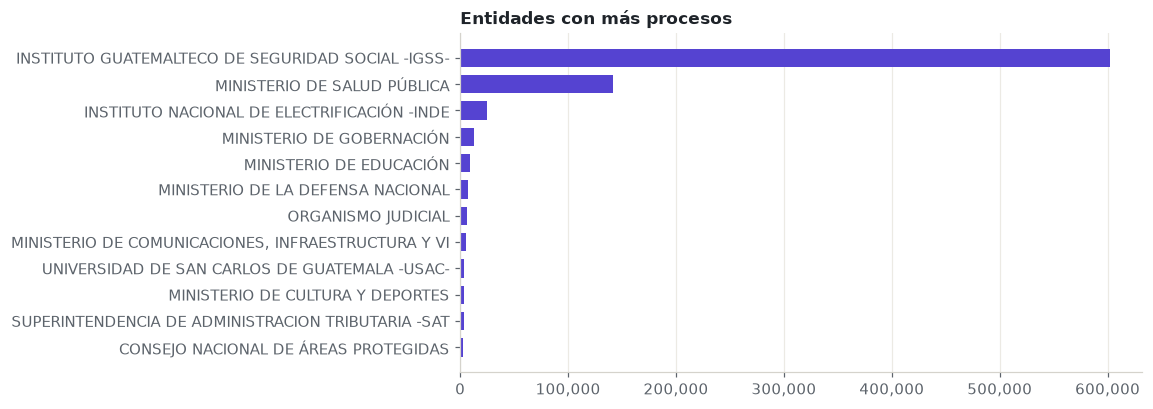

In [19]:
# --- 3.13 Entidades compradoras ---
entidades = df["entidad"].value_counts()
print(f"Entidades: {len(entidades):,} · las 10 primeras concentran {entidades.head(10).sum() / len(df):.1%}")
print(f"Solo el IGSS: {entidades.iloc[0] / len(df):.1%} · IGSS + Salud Pública: {entidades.head(2).sum() / len(df):.1%}")
top = entidades.head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top.index.str.slice(0, 50), top.values, color=ACENTO, height=0.7)
ax.set_title("Entidades con más procesos")
ax.xaxis.set_major_formatter(miles)
ax.grid(axis="y", visible=False)
fig.savefig(IMG / "entidades.png")
plt.show()

> ✍️ **[Milton: escribir]** Hallazgos del EDA (350–450 palabras): volumen real, peso de la compra directa, periodo para ofertar, poco texto por proceso, ruido, y sobre todo el cruce palabra clave/categoría con los casos de la tomografía.

## 4. Transformación de los datos

In [20]:
# --- 4.1 Texto de entrada ---
# Título + ítems + características, sin repetir lo que ya está en el título (description no viene).
ejemplos = df[df["items_texto"].fillna("").ne("") & df["titulo"].str.contains(RUIDO)].sample(4, random_state=7)
for fila in ejemplos.itertuples():
    print("TÍTULO :", fila.titulo[:200])
    print("ÍTEMS  :", (fila.items_texto or "")[:200])
    print("ENTRADA:", texto_entrada(fila.titulo, fila.items_texto, fila.caracteristicas)[:300], "\n")

TÍTULO : F-0714/2026	C-97463	ISRADIPINO CÁPSULA 5 MG
ÍTEMS  : Isradipino
ENTRADA: F-0714/2026	C-97463	ISRADIPINO CÁPSULA 5 MG | Concentración: 5 mg; Forma farmacéutica: Cápsula; Vía de administración: Oral; 

TÍTULO : RIVASTIGMINA SOLUCIÓN ORAL 2 MG/ML FRASCO DE 120 ML. CODIGO IGSS: 10518 P. 264/2024
ÍTEMS  : Rivastigmina
ENTRADA: RIVASTIGMINA SOLUCIÓN ORAL 2 MG/ML FRASCO DE 120 ML. CODIGO IGSS: 10518 P. 264/2024 | Concentración: 2mg/ml; Forma farmacéutica: Solución; Vía de administración: Oral; 

TÍTULO : PEDIDO 37436/2025 CODIGO IGSS 1531 CETRIMIDA CON CLORHEXIDINA (FORMULA 4) SOLUCION 0.5 O 0.05% RESPECTIVAMENTE, GALON. GALON
ÍTEMS  : Clorhexidina gluconato + cetrimida
ENTRADA: PEDIDO 37436/2025 CODIGO IGSS 1531 CETRIMIDA CON CLORHEXIDINA (FORMULA 4) SOLUCION 0.5 O 0.05% RESPECTIVAMENTE, GALON. GALON | Clorhexidina gluconato + cetrimida | Concentración: 0.05% + 0.5%;  Forma farmacéutica: Solución;  Vía de administración: Tópica; 

TÍTULO : CODIGO IGSS 106 AMOXICILINA, TABLETA O CÁPS

In [21]:
# --- 4.2 Las dos representaciones ---
# Embeddings: casi original. TF-IDF: minúsculas, lemas de spaCy, sin stopwords, sin tildes.
muestra_t = df.sample(20_000, random_state=RANDOM_STATE)
entrada = [texto_entrada(*f) for f in muestra_t[["titulo", "items_texto", "caracteristicas"]].itertuples(index=False)]
emb = [para_embedding(t) for t in entrada]
tfidf = para_tfidf(entrada)

comparacion = pd.DataFrame({"entrada": entrada, "embedding": emb, "tfidf": tfidf})
comparacion.loc[muestra_t["titulo"].str.contains(RUIDO).values].head(5)

,entrada,embedding,tfidf
0,"VALES DE COMIDA TIPO: ALIMENTO; RACIÓN PARA LAS PERSONAS PRIVADAS DE LIBERTAD DEL CENTRO DE ORIENTACIÓN FEMENINO, C....","VALES DE COMIDA TIPO: ALIMENTO; RACIÓN PARA LAS PERSONAS PRIVADAS DE LIBERTAD DEL CENTRO DE ORIENTACIÓN FEMENINO, C....",val comida tipo alimento racion persona privado libertad centro orientacion femenino mujer fraijan departamento guat...
5,REPARACIÓN DE: CUNA DE CALOR RADIANTE MODELO SM-401 (UNOPS). MEDIX S/S BIEN NO. 444824 | REPARACIÓN DE: CUNA DE CALO...,REPARACIÓN DE: CUNA DE CALOR RADIANTE MODELO SM-401 (UNOPS). MEDIX S/S | REPARACIÓN DE: CUNA DE CALOR RADIANTE MODEL...,reparacion cuna calor radiante modelo unops medix reparacion cuna calor radiante modelo unops medix consistente camb...
7,"MSPAS No. 2025-HES-CD546 ARRENDAMIENTO DE 8 VENTILADORES PULMONARES, 8 MONITORES DE SIGNOS VITALES, 8 ASPIRADORES DE...","ARRENDAMIENTO DE 8 VENTILADORES PULMONARES, 8 MONITORES DE SIGNOS VITALES, 8 ASPIRADORES DE SECRESIONES Y 8 ATRILES,...",arrendamiento ventilador pulmonar monitor signo vital aspirador secresion atril observacion emergencia adulto
13,"EVENTO NO. 1279/2025, CODIGO IGSS 6365, PEDIDO 63701, REFERENCIA 1368, CANTIDAD 6080, CATÉTER INTRAVENOSO NO. 24G X ...","CANTIDAD 6080, CATÉTER INTRAVENOSO NO. 24G X 3/4"" CON AGUJA SILICONIZADA Y CÁMARA DE FLUJO TRANSPARENTE, DE TEFLÓN O...",cantidad cateter intravenoso aguja siliconizado camara flujo transparente teflon poliuretano acoplir tipo luer lock ...
14,"CODIGO IGSS 354 METFORMINA, TABLETA DE LIBERACIÓN PROLONGADA 1000 MG. SOLICITUD: 5816/2025<br /> | Concentración: 10...","METFORMINA, TABLETA DE LIBERACIÓN PROLONGADA 1000 MG. | Concentración: 1000mg; Forma farmacéutica: Tabletas de liber...",metformin tableto liberacion prolongado mg concentracion mg forma farmaceutico tableta liberacion prolongado via adm...


In [22]:
# --- 4.3 Efecto en el vocabulario ---
def vocab(textos, tokenizar=str.split):
    tokens = [tok for t in textos for tok in tokenizar(t)]
    return len(tokens), len(set(tokens))

pasos = {
    "crudo (split)": vocab(entrada),
    "minúsculas": vocab([t.lower() for t in entrada]),
    "sin ruido + minúsculas": vocab([e.lower() for e in emb]),
    "lemas, sin stopwords ni tildes": vocab(tfidf),
}
tabla_vocab = pd.DataFrame(pasos, index=["tokens", "tipos"]).T
tabla_vocab["tokens por doc"] = (tabla_vocab["tokens"] / len(entrada)).round(1)
tabla_vocab

,tokens,tipos,tokens por doc
crudo (split),794908,75117,39.7
minúsculas,794908,60905,39.7
sin ruido + minúsculas,747734,46583,37.4
"lemas, sin stopwords ni tildes",453165,16555,22.7


In [23]:
# --- 4.4 Errores del lematizador ---
# es_core_news_sm se equivoca con algunos sustantivos; se documenta como limitación.
frases = ["Compra de una cafetera", "Metformina, tableta de liberación prolongada",
          "Licencias de software y computadoras portátiles", "Desarrollo de sistemas informáticos"]
for frase, lemas in zip(frases, para_tfidf(frases)):
    print(f"{frase:<50} → {lemas}")

Compra de una cafetera                             → compra cafetero
Metformina, tableta de liberación prolongada       → metformin tableto liberacion prolongado
Licencias de software y computadoras portátiles    → licencia software computadora portatil
Desarrollo de sistemas informáticos                → desarrollo sistema informatico


> ✍️ **[Milton: escribir]** Decisiones de transformación (350–450 palabras): por qué dos representaciones, qué ruido se quita y por qué, el tope de 1,000 caracteres, el efecto en el vocabulario (tabla 4.3) y los errores del lematizador. Cerrar con próximos pasos: etiquetado y modelo.